# 01 — Training walkthrough

This notebook explains what `train.py` did for each of the four disease heads (CVD, T2D, RESP, NEURO).
It **does not retrain anything**: it loads the frozen cohort, the saved patient split and the four saved
model bundles, and shows each step with its result.

| Step | What you see |
| --- | --- |
| 1 | The frozen cohort, verified by its SHA-256 |
| 2 | How raw visits become model features (missingness flags, velocity) |
| 3 | The patient split and disease rates in each partition |
| 4 | The features each head receives |
| 5 | How Optuna's tuning improved over 100 trials |
| 6 | Saved bundles checked against their records, and CV scores against the §3.7.1 targets |
| 7 | Calibration: raw vs calibrated probabilities |
| 8 | Conformal "Uncertain" zone and risk tiers on the risk scale |
| 9 | One patient from start to finish, with SHAP reasons |

The **holdout partition is never used here**. It is scored once, at the end of `02_gate_evaluation.ipynb`.
Steps 7–9 use the `calib_conf` partition, which the calibrator never saw.

Run with **Restart & Run All**. Figures are saved to `experiment/reports/figures/`.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# Find the project root from wherever the notebook is opened
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiment").is_dir())
sys.path.insert(0, str(ROOT / "experiment" / "src" / "ml"))
import data as D      # the same feature code the backend uses
import train as T     # metrics, thresholds and paths from training

FIG_DIR = ROOT / "experiment" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
HEADS = D.DISEASES
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", ROOT)
print("Models:", T.MODELS_DIR)

Project root: /home/nirmata/Desktop/thesis draft-1
Models: /home/nirmata/Desktop/thesis draft-1/experiment/data/models


## Step 1 — Load the frozen cohort

`load_cohort()` computes the file's SHA-256 and **stops** if it is not the frozen v11 cohort
(`23d28b00…`). Every number below therefore comes from exactly the data the models were trained on.

In [2]:
cohort = D.load_cohort()
print(f"{len(cohort):,} encounters, {cohort.patient_id.nunique():,} patients, {cohort.shape[1]} columns")
cohort.head()

23,996 encounters, 15,000 patients, 49 columns


,patient_id,biological_sex,age,bmi,systolic_bp,diastolic_bp,resting_hr,total_cholesterol,hdl,ldl,tg,egfr,hba1c,fpg,fev1,fvc,fev1_fvc_ratio,spo2,phq9,gad7,mmse,sleep_hours,bio_fhrs_cvd,adjusted_fhrs_cvd,fhrs_band_cvd,bio_fhrs_t2d,adjusted_fhrs_t2d,fhrs_band_t2d,bio_fhrs_resp,adjusted_fhrs_resp,fhrs_band_resp,bio_fhrs_neuro,adjusted_fhrs_neuro,fhrs_band_neuro,y_cvd,y_t2d,y_resp,y_neuro,visit_number,days_since_baseline,ldl_measured,tg_measured,fpg_measured,total_cholesterol_measured,bmi_measured,spirometry_measured,spo2_measured,phq9_measured,gad7_measured
0,PT-20260000,0,59,28.328909,127.095472,77.423213,79.334462,NaN,74.292118,87.97938,NaN,92.162376,5.808393,89.106749,2.958212,3.337479,88.636121,NaN,7.0,NaN,30,5.843702,0.0000,0.000000,0,0.25,0.319068,1,0.00000,0.000000,0,0.000,0.000000,0,0,0,0,0,1,0,1,0,1,0,1,1,0,1,0
1,PT-20260000,0,60,28.478909,127.695472,77.423213,79.334462,182.271499,74.292118,87.97938,NaN,91.362376,5.828393,NaN,2.958212,3.337479,88.636121,NaN,NaN,NaN,30,5.843702,0.0000,0.000000,0,0.25,0.319068,1,0.00000,0.000000,0,0.000,0.000000,0,0,0,0,0,2,365,1,0,0,1,1,1,0,0,0
2,PT-20260001,1,68,33.711067,150.112227,84.054140,84.219626,NaN,67.000298,NaN,NaN,70.585489,5.644663,98.359791,2.244808,3.093202,72.572312,99.128884,NaN,11.0,16,6.125901,0.5000,0.782693,1,0.00,0.000000,0,0.68750,1.008382,1,0.750,1.230313,1,0,0,1,0,1,0,0,0,1,0,1,1,1,0,1
3,PT-20260002,0,34,NaN,101.441624,65.602261,72.012968,NaN,82.352022,NaN,126.485685,91.264876,5.585536,NaN,3.355258,4.526417,74.126145,97.481642,NaN,NaN,26,6.332562,0.8125,1.314264,1,1.50,1.936553,2,0.46875,0.659718,1,0.125,0.184322,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0
4,PT-20260002,0,35,28.461441,102.041624,65.602261,72.012968,NaN,82.352022,NaN,NaN,90.464876,5.605536,NaN,3.355258,4.526417,74.126145,NaN,NaN,NaN,26,6.332562,0.8125,1.314264,1,1.50,1.936553,2,0.46875,0.659718,1,0.125,0.184322,1,0,0,0,0,2,365,0,0,0,0,1,1,0,0,0


## Step 2 — From raw visits to model features

Two kinds of columns are added (§3.3.2, §3.5.2):

- **Missingness flags** `m_<test>`: 1 when the test was *not* done, 0 when it was. The cohort stores the
  opposite (`<test>_measured`), so it is flipped to match the paper.
- **Velocity** `v_<marker>`: change since the patient's first visit, per month. Only computed for
  biomarkers that actually change between visits; missing (`NaN`) at the first visit, with `m_velocity = 1`.

Below: one patient with three visits. Note `v_…` is empty at visit 1, and `m_fpg` is 1 exactly where `fpg` is missing.

In [3]:
df, VEL = D.add_derived(cohort)
print("Velocity computed for:", VEL)

pid = df.loc[df.visit_number == 3, "patient_id"].iloc[0]
show = ["visit_number", "days_since_baseline", "systolic_bp", "v_systolic_bp",
        "hba1c", "v_hba1c", "fpg", "fpg_measured", "m_fpg", "m_velocity"]
df.loc[df.patient_id == pid, [c for c in show if c in df.columns]]

Velocity computed for: ['bmi', 'egfr', 'hba1c', 'systolic_bp']


,visit_number,days_since_baseline,systolic_bp,v_systolic_bp,hba1c,v_hba1c,fpg,fpg_measured,m_fpg,m_velocity
3,1,0,101.441624,NaN,5.585536,NaN,NaN,0,1,1
4,2,365,102.041624,0.050034,5.605536,0.001668,NaN,0,1,0
5,3,730,102.641624,0.050034,5.625536,0.001668,84.01725,1,0,0
6,4,1095,103.241624,0.050034,5.645536,0.001668,84.01725,1,0,0


## Step 3 — The patient split

One split is shared by all four heads: **70% train, 7.5% calibration A (isotonic/sigmoid),
7.5% calibration B (conformal), 15% holdout**. All visits of a patient stay in one partition, so a model is
never tested on a patient it has already seen. The split is stratified on the four labels together, which is
why each disease's rate is nearly the same in every partition.

The cell also checks that recomputing the split gives exactly the saved `partitions.csv`.

In [4]:
part = D.make_partitions(df)
saved = pd.read_csv(D.PROCESSED_DIR / "partitions.csv").set_index("patient_id")["partition"]
assert (part.sort_index() == saved.sort_index()).all(), "Split differs from the saved partitions.csv"

row_part = df["patient_id"].map(part)
labels = D.patient_labels(df)
order = ["train", "calib_iso", "calib_conf", "holdout"]
split = pd.DataFrame({"patients": part.value_counts(), "encounters": row_part.value_counts()}).loc[order]
for d in HEADS:
    split[f"{d.upper()} rate"] = labels[f"y_{d}"].groupby(part).mean().loc[order].round(3)
split

,patients,encounters,CVD rate,T2D rate,RESP rate,NEURO rate
train,10500,16826,0.084,0.103,0.124,0.071
calib_iso,1125,1843,0.084,0.105,0.124,0.072
calib_conf,1125,1761,0.086,0.102,0.124,0.070
holdout,2250,3566,0.085,0.103,0.124,0.071


## Step 4 — What each head sees

Each head gets its domain tests (§3.6.1 masks) plus a shared core: age, sex, `adjusted_fhrs_<d>`,
`fhrs_band_<d>`, the missingness flags for its own tests, and velocity where it exists.
`bio_fhrs` is deliberately left out, because the generator used it to create the labels (§3.7.2).

RESP and NEURO have **no velocity**: their markers do not change between visits in this cohort.

In [5]:
feat_rows = []
for d in HEADS:
    cols = D.feature_columns(d, VEL)
    feat_rows.append({
        "head": d.upper(),
        "n features": len(cols),
        "domain tests": ", ".join(D.MASKS[d]),
        "family history": ", ".join(c for c in cols if "fhrs" in c),
        "missing flags": ", ".join(c for c in cols if c.startswith("m_") and c != "m_velocity"),
        "velocity": ", ".join(c for c in cols if c.startswith("v_")) or "none",
    })
pd.DataFrame(feat_rows).set_index("head")

,n features,domain tests,family history,missing flags,velocity
head,,,,,
CVD,18,"systolic_bp, diastolic_bp, resting_hr, total_c...","adjusted_fhrs_cvd, fhrs_band_cvd","m_ldl, m_tg, m_total_cholesterol","v_systolic_bp, v_egfr"
T2D,15,"hba1c, fpg, bmi, tg, hdl","adjusted_fhrs_t2d, fhrs_band_t2d","m_bmi, m_fpg, m_tg","v_hba1c, v_bmi"
RESP,10,"fev1, fvc, fev1_fvc_ratio, spo2","adjusted_fhrs_resp, fhrs_band_resp","m_spirometry, m_spo2",none
NEURO,10,"mmse, phq9, gad7, sleep_hours","adjusted_fhrs_neuro, fhrs_band_neuro","m_gad7, m_phq9",none


## Step 5 — How Optuna tuned each head

Each dot is one of the 100 settings Optuna tried; the black line is the best score found so far.
The score is the §3.6.4 loss (lower is better):
`0.35(1−AUROC) + 0.25(1−AUPRC) + 0.20·ECE + 0.10·Brier + 0.10·subgroup gap`.

**What to look for:** the line drops quickly in the first 20–40 trials and then flattens.
A flat tail means more trials would add little, so 100 was enough.

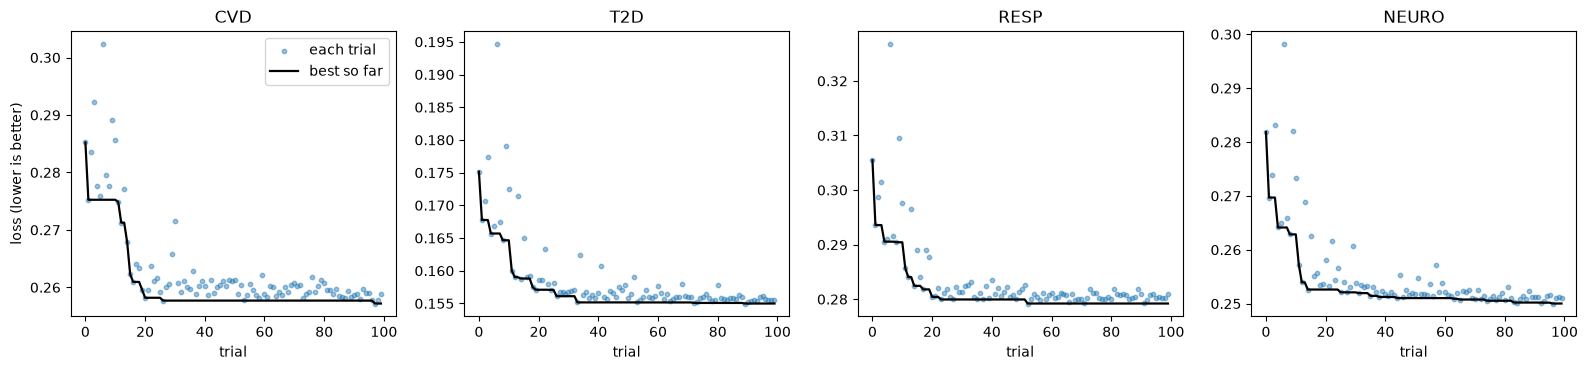

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, d in zip(axes, HEADS):
    h = pd.read_csv(T.MODELS_DIR / f"{d}_trials.csv").sort_values("trial")
    ax.scatter(h["trial"], h["loss"], s=10, alpha=0.45, label="each trial")
    ax.plot(h["trial"], h["loss"].cummin(), color="black", lw=1.6, label="best so far")
    ax.set_title(d.upper())
    ax.set_xlabel("trial")
axes[0].set_ylabel("loss (lower is better)")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_tuning_history.png", dpi=200)
plt.show()

The settings Optuna chose for each head:

In [7]:
records = {d: json.loads((T.MODELS_DIR / f"{d}_head_latest.json").read_text()) for d in HEADS}
pd.DataFrame({d.upper(): records[d]["best_params"] for d in HEADS}).round(4)

,CVD,T2D,RESP,NEURO
n_estimators,300.0000,450.0000,150.0000,450.0000
max_depth,2.0000,2.0000,2.0000,2.0000
learning_rate,0.0168,0.0110,0.0325,0.0246
subsample,0.6718,0.7779,0.8013,0.9181
colsample_bytree,0.9501,0.9658,0.7960,0.8258
min_child_weight,2.0544,5.4346,11.6433,18.1425
reg_lambda,0.0050,0.0053,0.0115,0.0060
gamma,0.6996,2.7849,3.0125,4.3480
scale_pos_weight,1.7710,1.0730,1.3633,2.5067


## Step 6 — Saved bundles and their cross-validation scores

Each bundle file is checked against the SHA-256 stored in its `.json` record, so you know the file on disk is
the one that was trained.

The table compares the **CV scores** (training partition, 5 folds) with the §3.7.1 targets.
These are a preview only: the official gate check, with confidence intervals, calibration slope,
decision curves and stability, is in `02_gate_evaluation.ipynb`.

In [8]:
bundles = {}
for d in HEADS:
    path = T.MODELS_DIR / f"{d}_head_latest.joblib"
    assert D.sha256_of(path) == records[d]["artifact_sha256"], f"{d}: file does not match its record"
    bundles[d] = joblib.load(path)
print("All four bundles match their records.")

AUROC_TARGET = {"cvd": 0.80, "t2d": 0.80, "resp": 0.75, "neuro": 0.70}
mark = lambda ok: "pass" if ok else "FAIL"
rows = []
for d in HEADS:
    cv = records[d]["cv_metrics"]
    pi = df.loc[row_part == "train", "patient_id"].map(labels[f"y_{d}"]).mean()   # training-row prevalence
    rows.append({
        "head": d.upper(),
        "AUROC": f'{cv["auroc"]:.3f} (≥{AUROC_TARGET[d]:.2f}) {mark(cv["auroc"] >= AUROC_TARGET[d])}',
        "AUPRC": f'{cv["auprc"]:.3f} (≥{2*pi:.3f}) {mark(cv["auprc"] >= 2*pi)}',
        "ECE": f'{cv["ece"]:.3f} (≤0.05) {mark(cv["ece"] <= 0.05)}',
        "Brier": f'{cv["brier"]:.4f} (<{pi*(1-pi):.4f}) {mark(cv["brier"] < pi*(1-pi))}',
        "subgroup gap": f'{cv["subgroup_gap"]:.3f} (<0.05) {mark(cv["subgroup_gap"] < 0.05)}',
        "calibration": records[d]["calibration_method"],
    })
pd.DataFrame(rows).set_index("head")

All four bundles match their records.


,AUROC,AUPRC,ECE,Brier,subgroup gap,calibration
head,,,,,,
CVD,0.810 (≥0.80) pass,0.321 (≥0.175) pass,0.019 (≤0.05) pass,0.0709 (<0.0798) pass,0.102 (<0.05) FAIL,sigmoid
T2D,0.875 (≥0.80) pass,0.617 (≥0.214) pass,0.017 (≤0.05) pass,0.0627 (<0.0954) pass,0.058 (<0.05) FAIL,isotonic
RESP,0.736 (≥0.75) FAIL,0.325 (≥0.248) pass,0.018 (≤0.05) pass,0.0979 (<0.1086) pass,0.048 (<0.05) pass,isotonic
NEURO,0.813 (≥0.70) pass,0.331 (≥0.144) pass,0.012 (≤0.05) pass,0.0577 (<0.0667) pass,0.091 (<0.05) FAIL,sigmoid


## Step 7 — Calibration: does "30% risk" mean about 30 in 100?

Each point groups 10% of the `calib_conf` patients by predicted risk and compares the average prediction
(x) with how many of them actually have the disease (y). A perfectly calibrated model lies on the dashed line.

**What to look for:** the raw XGBoost curve sits to the right of the line, because `scale_pos_weight`
deliberately pushes raw scores up (§3.3.4). After calibration the points move onto the line and ECE drops.

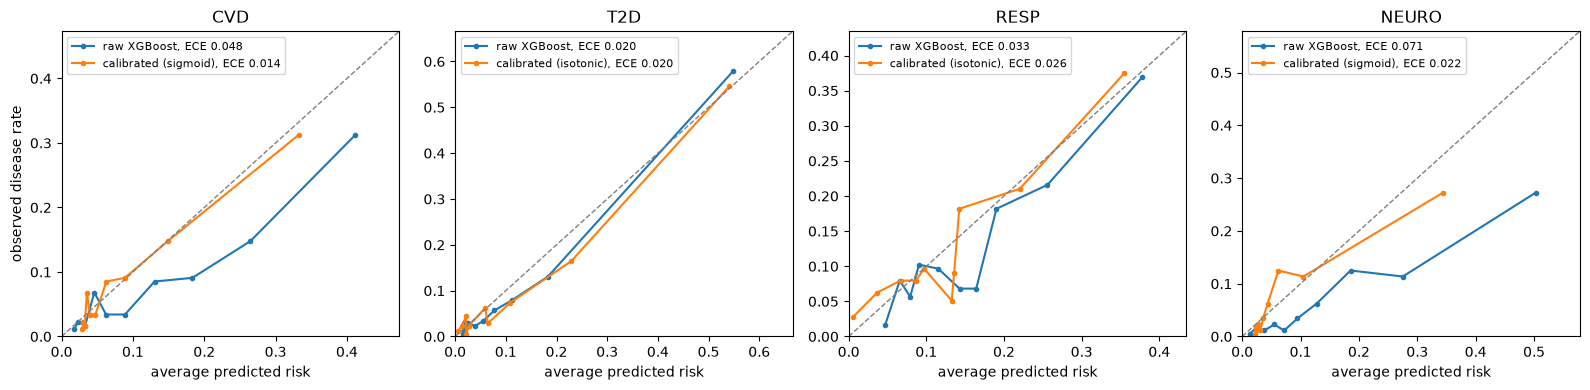

In [9]:
def reliability(y, p, n_bins=10):
    order = np.argsort(p, kind="stable")
    groups = np.array_split(order, n_bins)
    return np.array([p[g].mean() for g in groups]), np.array([y[g].mean() for g in groups])

conf = (row_part == "calib_conf").to_numpy()
P_CAL = {}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, d in zip(axes, HEADS):
    b = bundles[d]
    X = df.loc[conf, b["feature_columns"]].astype(float)
    y = df.loc[conf, "patient_id"].map(labels[f"y_{d}"]).to_numpy()
    p_raw = b["raw"].predict_proba(X)[:, 1]
    p_cal = b["calibrated"].predict_proba(X)[:, 1]
    P_CAL[d] = (p_cal, y)
    top = 0
    for p, name in [(p_raw, "raw XGBoost"), (p_cal, f'calibrated ({records[d]["calibration_method"]})')]:
        mp, fy = reliability(y, p)
        ax.plot(mp, fy, marker="o", ms=3, label=f"{name}, ECE {T.ece(y, p):.3f}")
        top = max(top, mp.max(), fy.max())
    lim = min(1.0, top * 1.15)
    ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=1)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(d.upper()); ax.set_xlabel("average predicted risk")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("observed disease rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_calibration_curves.png", dpi=200)
plt.show()

## Step 8 — Where the "Uncertain" flag and the risk tiers fall

The conformal thresholds q̂₀ and q̂₁ (fitted on `calib_conf`) split the risk scale into three zones:

- ŷ below **1 − q̂₁** → set {0}: confidently does not have the disease
- between **1 − q̂₁** and **q̂₀** → set {0, 1}: **Uncertain**
- above **q̂₀** → set {1}

The orange band is the Uncertain zone; the dashed lines are the tier cutoffs (Low < 0.20 ≤ Moderate < 0.50 ≤ High).
The bars show how calibrated risks are spread across `calib_conf` patients (log scale).

**What to look for:** the Uncertain band covers the low end of the scale. For CVD and NEURO it lies inside
the Low tier; for T2D and RESP it reaches a little past 0.20 into Moderate. In practice the flag means
"lowish score, but the model cannot rule the disease out".

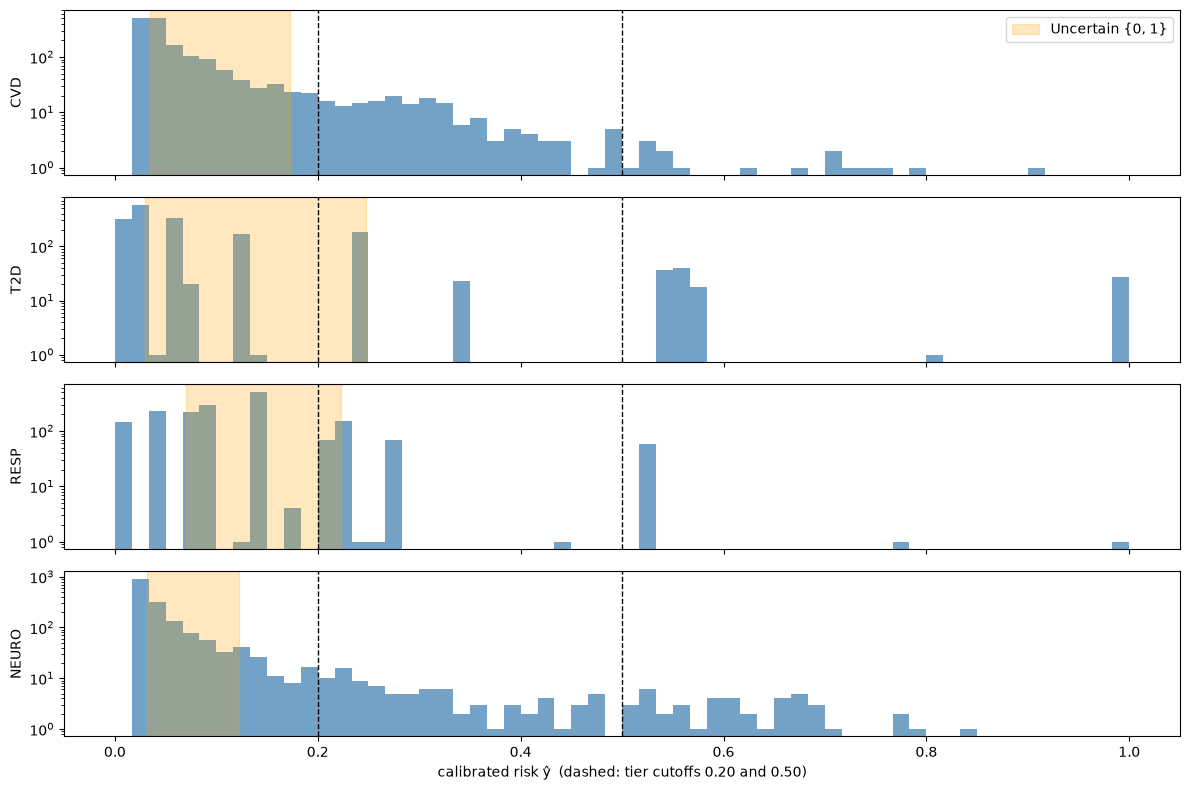

,{0} if ŷ <,{1} if ŷ >,Uncertain share,Low,Moderate,High,"coverage, sick patients","coverage, healthy patients"
head,,,,,,,,
CVD,0.035,0.173,0.538,0.897,0.094,0.009,0.910,0.901
T2D,0.030,0.248,0.462,0.814,0.117,0.069,0.908,0.957
RESP,0.071,0.223,0.712,0.800,0.166,0.034,0.914,0.947
NEURO,0.032,0.122,0.392,0.926,0.050,0.024,0.908,0.901


In [10]:
zone_rows = []
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, d in zip(axes, HEADS):
    b = bundles[d]
    q0, q1 = b["q_hat"]["0"], b["q_hat"]["1"]
    lo, hi = 1 - q1, q0
    p, y = P_CAL[d]
    ax.hist(p, bins=60, range=(0, 1), color="steelblue", alpha=0.75)
    ax.axvspan(min(lo, hi), max(lo, hi), color="orange", alpha=0.25, label="Uncertain {0, 1}")
    for c in b["tier_cutoffs"]:
        ax.axvline(c, color="black", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_ylabel(d.upper())
    sets = [tuple(T.prediction_set(v, b["q_hat"])) for v in p]
    zone_rows.append({
        "head": d.upper(),
        "{0} if ŷ <": round(lo, 3), "{1} if ŷ >": round(hi, 3),
        "Uncertain share": round(np.mean([s == (0, 1) for s in sets]), 3),
        "Low": round((p < 0.20).mean(), 3),
        "Moderate": round(((p >= 0.20) & (p < 0.50)).mean(), 3),
        "High": round((p >= 0.50).mean(), 3),
        "coverage, sick patients": round(np.mean([1 in s for s, t in zip(sets, y) if t == 1]), 3),
        "coverage, healthy patients": round(np.mean([0 in s for s, t in zip(sets, y) if t == 0]), 3),
    })
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("calibrated risk ŷ  (dashed: tier cutoffs 0.20 and 0.50)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_conformal_zones.png", dpi=200)
plt.show()
pd.DataFrame(zone_rows).set_index("head")

Coverage here is measured on the same rows that set the thresholds, so it is close to 0.90 by construction.
The real coverage check is on the holdout, in notebook 02.

## Step 9 — One patient from start to finish

A patient with T2D from `calib_conf`: the feature row the model receives, the calibrated risk, the tier,
the conformal set, and the SHAP reasons. Change `HEAD` to look at another disease.

SHAP values are computed by XGBoost itself (exact TreeSHAP). They explain the **raw** model score in
log-odds, which is the score before calibration, so they add up to the raw log-odds, not to ŷ.

In [11]:
HEAD = "t2d"
b = bundles[HEAD]
is_pos = df["patient_id"].map(labels[f"y_{HEAD}"]) == 1
idx = df.index[conf & is_pos.to_numpy()][0]
x = df.loc[[idx], b["feature_columns"]].astype(float)
p = b["calibrated"].predict_proba(x)[0, 1]
print(f"Patient {df.at[idx, 'patient_id']}, visit {df.at[idx, 'visit_number']}")
print(f"Calibrated risk ŷ = {p:.3f}  →  {T.risk_tier(p)} risk, conformal set {T.prediction_set(p, b['q_hat'])}")
x.T.rename(columns={idx: "value"})

Patient PT-20260194, visit 1
Calibrated risk ŷ = 0.810  →  High risk, conformal set [1]


,value
age,78.000000
biological_sex,0.000000
hba1c,7.805551
fpg,152.954102
bmi,NaN
tg,198.061467
hdl,47.841571
adjusted_fhrs_t2d,4.150999
fhrs_band_t2d,3.000000
m_bmi,1.000000


Baseline φ0 = -2.113; φ0 + Σφ = +1.577 (raw log-odds)


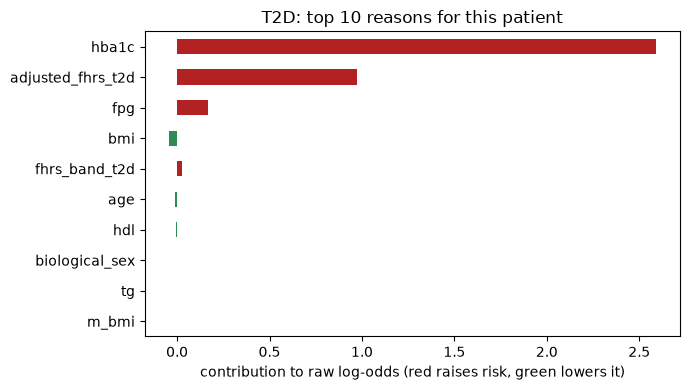

In [12]:
try:
    import xgboost as xgb
    booster = b["raw"].get_booster()
    contrib = booster.predict(xgb.DMatrix(x), pred_contribs=True)[0]   # last entry is the baseline φ0
    phi = pd.Series(contrib[:-1], index=b["feature_columns"])
    top = phi.reindex(phi.abs().sort_values(ascending=False).index).head(10)[::-1]
    print(f"Baseline φ0 = {contrib[-1]:+.3f}; φ0 + Σφ = {contrib.sum():+.3f} (raw log-odds)")
    ax = top.plot.barh(color=["firebrick" if v > 0 else "seagreen" for v in top], figsize=(7, 4))
    ax.set_xlabel("contribution to raw log-odds (red raises risk, green lowers it)")
    ax.set_title(f"{HEAD.upper()}: top 10 reasons for this patient")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"01_shap_example_{HEAD}.png", dpi=200)
    plt.show()
except Exception as e:
    print("SHAP step skipped:", e)

## Summary

- The cohort, the split and all four bundles match their saved hashes and records.
- Every head is well calibrated after the calibration step.
- The CV preview flags the subgroup gap (CVD, T2D, NEURO) and RESP's AUROC; notebook 02 checks these properly.

**Next:** `02_gate_evaluation.ipynb` — the eight gates with confidence intervals, the subgroup breakdown,
the FHRS ablation, the logistic-regression baselines, and the single holdout evaluation.